In [19]:
import sys
from collections import OrderedDict as odict

import ehtim.const_def as ehc
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from flax import linen as nn
from jax_finufft import nufft2
from matplotlib.colors import LogNorm

sys.path.insert(0, '..')  # Run from notebooks/
import kine.model as mo
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi

if not hasattr(jax, 'tree_map'):
    jax.tree_map = jax.tree.map  # Compatibility with this JAX version

### Step 1: XX and YY $\rightarrow$ Stokes I

In [20]:
# Read data, first line is column names
data = np.loadtxt('../data/DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt', skiprows=1)

# Sample fourier coordinates, in wavelengths
u, v = data[:, 4], data[:, 5]

xx = data[:, 6] + 1j * data[:, 7]
yy = data[:, 8] + 1j * data[:, 9]
w_xx = data[:, 10]
w_yy = data[:, 11]

print(f'{len(data)} rows')

vis_i = (xx + yy) / 2
sigma_i = np.sqrt(1 / w_xx + 1 / w_yy) / 2

6486 rows


### Step 2: Picking an image grid

In [21]:
resolution_arcsec = np.rad2deg(1 / np.hypot(u, v).max()) * 3600
npix, fov_arcsec = 64, 2.0  # Grid of 64 pixels across 2 arcseconds

pixel_size = np.deg2rad(fov_arcsec / 3600) / npix
print(f'Nominal resolution: {resolution_arcsec:.3f} arcsec; pixel: {fov_arcsec / npix:.5f} arcsec')

grid = jnp.asarray(ut.get_grid(npix, npix), dtype=jnp.float32)

Nominal resolution: 0.094 arcsec; pixel: 0.03125 arcsec


### Step 3: Image $\rightarrow$ visibilities (without A)

* `get_uvpoints` (in `obsdata.py`) converts coordinates for NUFFT: $u'=2\pi p u$ and $v'=2\pi p v$
* `get_pulsefac` (in `obsdata.py`) makes sure NUFFT’s pixels match Kine (triangular profile): $P(u',v')=\text{pulse}(u',v')\,e^{-i(u'+v')/2}$

We copy both directly for our table. We then use the forward model from `trainer.py`. The tolerance is increased (just to ensure we agree with the direct A method). 

TODO for Kahaan: understand the code better (seems to work though).

In [22]:
# Copied from Obsdata.get_uvpoints (596-598)
scaled_u = 2 * np.pi * u * pixel_size
scaled_v = 2 * np.pi * v * pixel_size

# Copied from Obsdata.get_pulsefac (612-615)
pulse = np.array([
    ehc.PULSE_DEFAULT(ui, vi, 1., dom='F') * np.exp(-0.5j * (ui + vi))
    for ui, vi in zip(scaled_u, scaled_v)
])

# Send to JAX
u_nufft = jnp.asarray(scaled_u, dtype=jnp.float32)
v_nufft = jnp.asarray(scaled_v, dtype=jnp.float32)
pulse = jnp.asarray(pulse, dtype=jnp.complex64)
target = jnp.asarray(vis_i, dtype=jnp.complex64)
sigma = jnp.asarray(sigma_i, dtype=jnp.float32)

# Copied from trainer.py (830-831), but not with 1e-3 tolerance
def image_to_visibilities(image, u, v, pulse):
    image = jnp.asarray(image, dtype=jnp.complex64)
    return nufft2(image, v, u, eps=1e-6) * pulse

print(f'{len(target)} measured visibilities')

6486 measured visibilities


### Step 4: Construct the image model

In [23]:
network = mo.NeuralField(
    posenc_deg=(0, 0),  # No positional encoding
    outdim=1,
    depth=4,
    width=256,  # Good to keep fixed, lower priority to vary
    activ=nn.gelu,
    outactiv=nn.softplus,
    outshift=10,
    scaling_i=1.0,
)

# Initialize, where two-element dummy input represents one (x, y) coordinate
variables = network.init(jax.random.PRNGKey(1), jnp.ones(2, dtype=jnp.float32), train=True)

# Set learning rate schedule (maybe this is built into Trainer...not sure)
schedule = optax.piecewise_constant_schedule(1e-2, {150: 0.1})

state = tr.Trainer.create(
    apply_fn=network.apply,
    params=variables['params'],
    batch_stats=variables['batch_stats'],
    tx=optax.adamax(schedule),
)

### Step 5: Initialize and train the network

In [24]:
### WARM START, same as before

# Starting disk
init_params = {'fwhm': 800_000, 'blur': 100_000, 'posx': 0, 'posy': 0}

# Estimate ballpark of starting flux from the 50 shortest baselines
short = np.argsort(np.hypot(u, v))[:50]
init_flux = np.median(np.abs(vis_i[short]))

# Of the form: Image(nPixelsRow, full width of image, DL Tau RA, DL Tau DEC, nIterations)
# Then, trainer expects a JAX array
init_im = vi.Image(npix, np.deg2rad(fov_arcsec / 3600), 4.5609, 25.3439, 150)
init_im.add_tophat(init_flux, init_params)
initial = jnp.asarray(init_im.iarr, dtype=jnp.float32)

init_losses = []

for _ in range(150):
    init_loss, _, _, state = tr.Trainer.train_step(odict(state=state, grid=grid, init_arr=initial))
    init_losses.append(float(init_loss))

# Evaluate the network after the final update
init_output, _ = state.apply_fn(
    {'params': state.params, 'batch_stats': state.batch_stats},
    grid,
    train=True,
    mutable=['batch_stats'],  # We have update stats, but they aren't used (_)
)

We evaluate the network as a 64x64 image, apply the NUFFT to predict each complex visibility, and minimize the uncertainty-weighted loss in `_loss_vis_2d` (from `trainer.py`):
$$
\mathcal L=\frac{1}{2M}\sum_{m=1}^{M}
\left|\frac{V_{\mathrm{pred},m}-V_{I,m}}{\sigma_{I,m}}\right|^2
$$

Kine expects an A matrix, but the NUFFT does not need this. We need the model and optimizer from Kine, but compute the predicted visibilities ourselves. 

In [25]:
@jax.jit
def train_step_nufft(state):
    def loss_fn(params):
        # Evaluate the current neural field at every coordinate (grid is the image grid)
        output, updates = state.apply_fn(
            {'params': params, 'batch_stats': state.batch_stats},
            grid, train=True, mutable=['batch_stats'],
        )

        # Map flattened pixel fluxes --> 2D image for NUFFT
        image = output[:, 0].reshape(npix, npix)
        
        # Replace the A * image operation
        predicted = image_to_visibilities(image, u_nufft, v_nufft, pulse)

        # Same uncertainty-weighted complex-visibility loss as _loss_vis_2d
        loss = jnp.mean((jnp.abs(predicted - target) / sigma)**2) / 2
        return loss, updates

    (loss, updates), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)  # Differentiate loss w.r.t params
    batch_stats = jax.tree.map(lambda x: jnp.mean(x, axis=0), updates['batch_stats'])  # Average over pixels
    state = state.apply_gradients(grads=grads).replace(batch_stats=batch_stats)  # Apply one Adamax update
    return loss, state

vis_losses = []
for step in range(1, 601):
    loss, state = train_step_nufft(state)
    vis_losses.append(float(loss))
    if step == 1 or step % 50 == 0:
        print(f'Step {step}: visibility loss = {float(loss)}')

trained_output, _ = state.apply_fn(
    {'params': state.params, 'batch_stats': state.batch_stats},
    grid, train=True, mutable=['batch_stats'],
)

Step 1: visibility loss = 66.2406005859375
Step 50: visibility loss = 9.397750854492188
Step 100: visibility loss = 5.892904758453369
Step 150: visibility loss = 4.591180324554443
Step 200: visibility loss = 4.165092468261719
Step 250: visibility loss = 4.038311958312988
Step 300: visibility loss = 3.9711124897003174
Step 350: visibility loss = 3.924238681793213
Step 400: visibility loss = 3.8865466117858887
Step 450: visibility loss = 3.8537871837615967
Step 500: visibility loss = 3.8246068954467773
Step 550: visibility loss = 3.798443078994751
Step 600: visibility loss = 3.7746756076812744


### Step 6: View the image

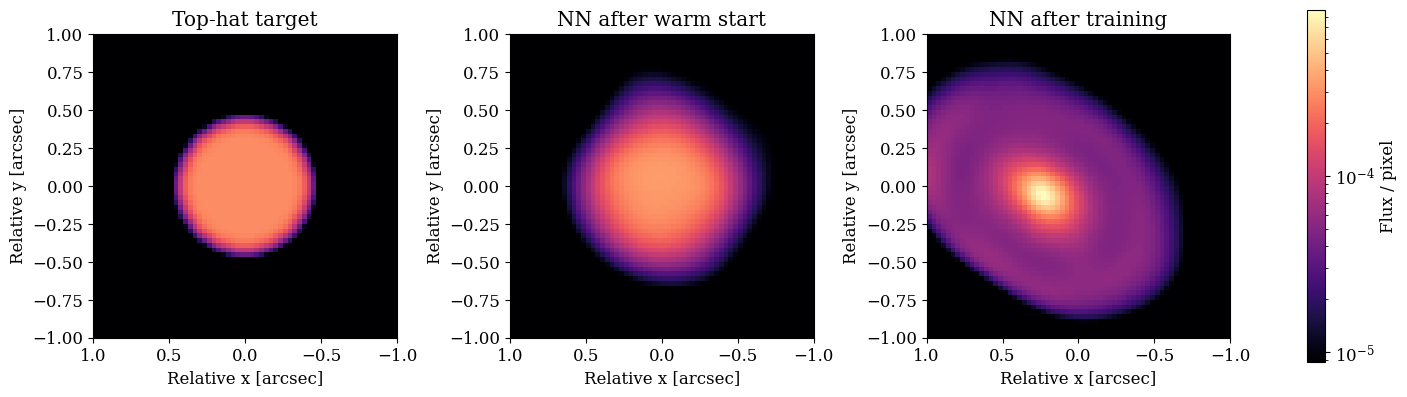

In [26]:
# Save the final 64×64 image for later comparison
image_64 = np.asarray(trained_output[:, 0]).reshape(npix, npix).copy()

images = [
    np.asarray(initial[..., 0]),
    np.asarray(init_output[:, 0]).reshape(npix, npix),
    image_64,
]
titles = ['Top-hat target', 'NN after warm start', 'NN after training']

# Sharing a log scale across all three images
peak = max(image.max() for image in images)
norm = LogNorm(vmin=0.01 * peak, vmax=peak, clip=True)
extent = (fov_arcsec / 2, -fov_arcsec / 2, -fov_arcsec / 2, fov_arcsec / 2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

for ax, image, title in zip(axes, images, titles):
    plot = ax.imshow(
        image,
        origin='upper',
        extent=extent,
        cmap='magma',
        norm=norm,
    )
    ax.set(title=title, xlabel='Relative x [arcsec]', ylabel='Relative y [arcsec]')

fig.colorbar(plot, ax=axes, label='Flux / pixel')
plt.show()

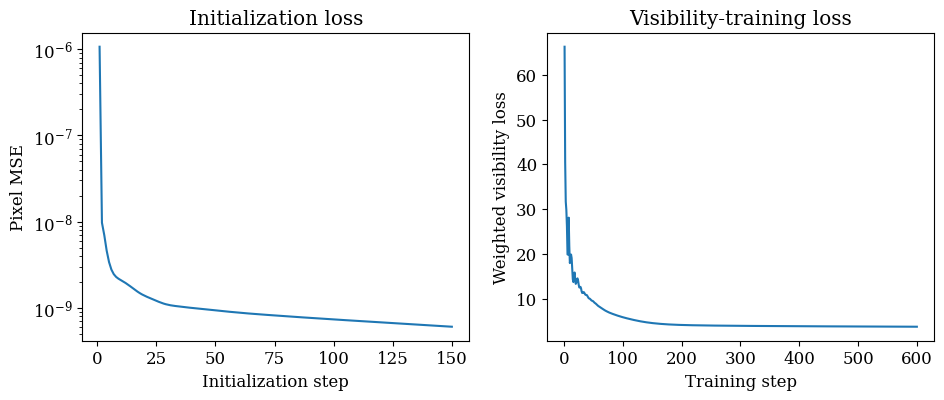

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(np.arange(1, len(init_losses) + 1), init_losses)
axes[0].set(
    title='Initialization loss',
    xlabel='Initialization step',
    ylabel='Pixel MSE',
)
axes[0].set_yscale('log')

axes[1].plot(np.arange(1, len(vis_losses) + 1), vis_losses)
axes[1].set(
    title='Visibility-training loss',
    xlabel='Training step',
    ylabel='Weighted visibility loss',
)

plt.show()